# code_123 · Lag boosting and neural multi-horizon forecasts

**Book:** section 24.3. A self-contained forecasting laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_24_GUIDE.md), [run evidence](../CHAPTER_24_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_123).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2723;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
import statsmodels
VERSIONS['statsmodels']=statsmodels.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2723


<a id="neural-forecast-contract"></a>
 ## Share origins and information before comparing model families
 Generate eight hourly building-demand series for42days. Context48 contains demand, observed weather and occupancy through origin−1. Known future calendar, preannounced occupancy and a prefix-only issued weather forecast accompany horizons1/6/24; building scale is known. Source targets end before672, development targets lie in672–839, final targets in840–1007, with issue origins every6hours. All building identities are seen during source fitting; this is temporal assessment. The same flattened information feeds native histogram boosting (one head per horizon), while GRU, causal TCN, history attention and patch attention learn shared context encoders and three-output heads. The patch encoder groups twelve consecutive three-channel samples into each of four tokens; it is not a full channel-independent PatchTST reproduction. Each neural family gets two rates/300 minibatch updates with shared batch schedules and its own development checkpoint. Boosting gets two leaf limits/100 rounds per head; fitting costs/capacities differ.


,model,development_MSE,final_MSE,MSE_by_horizon
0,Lag boosting,0.717021,0.471902,"[0.09253000523931146, 0.6141965216953309, 0.70..."
1,GRU,0.449084,0.311283,"[0.14091068621007238, 0.3840078720514471, 0.40..."
2,Causal TCN,0.468644,0.328307,"[0.24175053901402918, 0.3345075079988117, 0.40..."
3,History attention,0.476311,0.273926,"[0.11334868724105132, 0.3722729061729892, 0.33..."
4,Patch attention,0.473085,0.331385,"[0.10972358769056392, 0.3331106610308974, 0.55..."


,family,max_leaf_nodes,development_MSE,rate,best_step
0,Lag boosting,7.0,0.724373,NaN,NaN
1,Lag boosting,15.0,0.717021,NaN,NaN
2,GRU,NaN,0.485395,0.003,300.0
3,GRU,NaN,0.449084,0.010,240.0
4,Causal TCN,NaN,0.475238,0.003,160.0
5,Causal TCN,NaN,0.468644,0.010,100.0
6,History attention,NaN,0.477989,0.003,150.0
7,History attention,NaN,0.476311,0.010,80.0
8,Patch attention,NaN,0.473085,0.003,210.0
9,Patch attention,NaN,0.498729,0.010,80.0


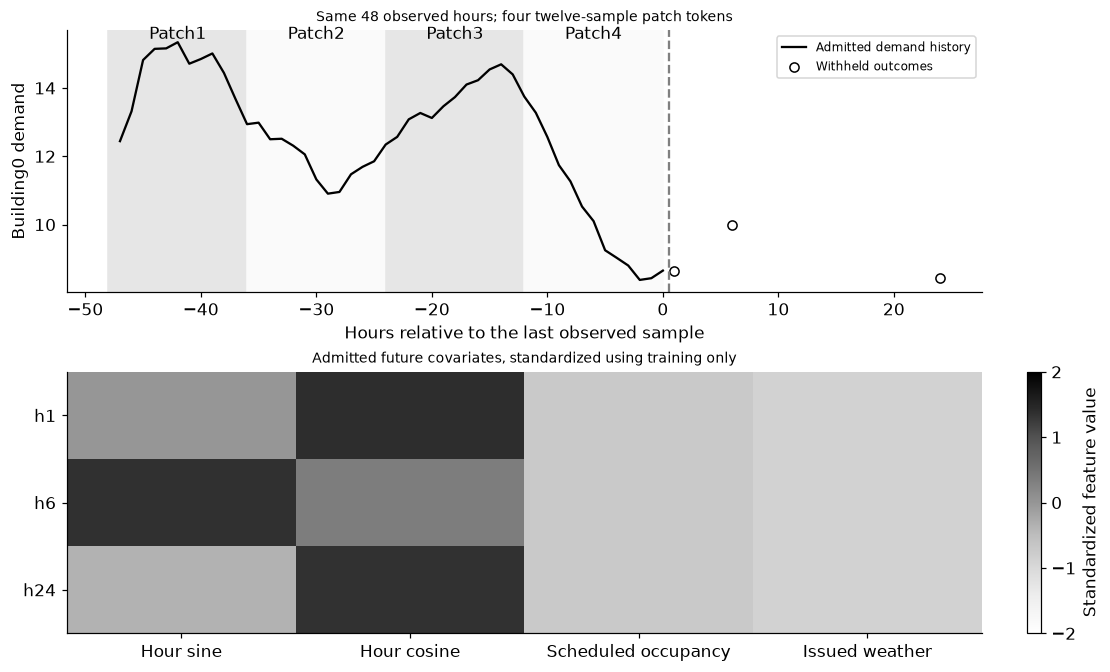

In [2]:
import copy
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from matplotlib.patches import Rectangle
B,T,L=8,1008,48;horizons=np.array([1,6,24]);time_index=np.arange(T);hour=time_index%24;day_active=rng.binomial(1,.8,T//24);occupancy=np.repeat(day_active,24)*((hour>=8)&(hour<18));weather_mean=12+4*np.sin(2*np.pi*time_index/(24*7));weather_deviation=np.zeros(T)
for t in range(1,T):weather_deviation[t]=.8*weather_deviation[t-1]+rng.normal(0,.7)
weather=weather_mean+weather_deviation;area=rng.uniform(.8,1.2,B);energy=np.zeros((B,T));energy[:,0]=10*area
for t in range(1,T):
    equilibrium=area*(10+2*occupancy[t]+1.5*np.sin(2*np.pi*hour[t]/24)+np.maximum(12-weather[t],0));energy[:,t]=.65*energy[:,t-1]+.35*equilibrium+rng.normal(0,.15,B)
def issued(origin):return weather_mean[origin+horizons-1]+.8**horizons*weather_deviation[origin-1]
def windows(origins):
    history=[];future=[];target=[];metadata=[]
    for origin in origins:
        times=origin+horizons-1;future_known=np.c_[np.sin(2*np.pi*(times%24)/24),np.cos(2*np.pi*(times%24)/24),occupancy[times],np.maximum(12-issued(origin),0)]
        for b in range(B):
            history.append(np.c_[energy[b,origin-L:origin],weather[origin-L:origin],occupancy[origin-L:origin]]);future.append(future_known);target.append(energy[b,times]);metadata.append((b,origin))
    return np.array(history),np.array(future),np.array(target),np.array(metadata)
train_origins=np.arange(L,672-24+1,6);dev_origins=np.arange(672,840-24+1,6);final_origins=np.arange(840,T-24+1,6);raw_train,future_train,y_train,meta_train=windows(train_origins);raw_dev,future_dev,y_dev,meta_dev=windows(dev_origins);raw_final,future_final,y_final,meta_final=windows(final_origins);history_scaler=StandardScaler().fit(raw_train.reshape(-1,3));future_scaler=StandardScaler().fit(future_train.reshape(-1,4));target_center=y_train.mean();target_scale=y_train.std();area_center=area[meta_train[:,0]].mean();area_scale=area[meta_train[:,0]].std()
def tensors(raw,future,target,metadata):
    history=torch.tensor(history_scaler.transform(raw.reshape(-1,3)).reshape(raw.shape));future_scaled=future_scaler.transform(future.reshape(-1,4)).reshape(len(future),-1);extra=torch.tensor(np.c_[future_scaled,(area[metadata[:,0]]-area_center)/area_scale]);return history,extra,torch.tensor((target-target_center)/target_scale)
tx,te,ty=tensors(raw_train,future_train,y_train,meta_train);dx,de,dy=tensors(raw_dev,future_dev,y_dev,meta_dev);fx,fe,fy=tensors(raw_final,future_final,y_final,meta_final);tree_train=torch.cat([tx.reshape(len(tx),-1),te],dim=1).numpy();tree_dev=torch.cat([dx.reshape(len(dx),-1),de],dim=1).numpy();tree_final=torch.cat([fx.reshape(len(fx),-1),fe],dim=1).numpy();candidates=[];predictions={};development_predictions={};complexity={}
best=np.inf
for leaves in [7,15]:
    models=[];dev_columns=[]
    for h in range(3):
        model=HistGradientBoostingRegressor(max_leaf_nodes=leaves,max_iter=100,learning_rate=.05,min_samples_leaf=10,l2_regularization=.1,early_stopping=False,random_state=SEED).fit(tree_train,y_train[:,h]);models.append(model);dev_columns.append(model.predict(tree_dev))
    prediction=np.array(dev_columns).T;score=float(np.mean((prediction-y_dev)**2));candidates.append({'family':'Lag boosting','max_leaf_nodes':leaves,'development_MSE':score})
    if score<best:best=score;tree_models=models;tree_dev_prediction=prediction;tree_leaves=leaves
predictions['Lag boosting']=np.array([model.predict(tree_final) for model in tree_models]).T;development_predictions['Lag boosting']=tree_dev_prediction;complexity['Lag boosting']={'heads':3,'rounds_per_head':100,'selected_max_leaf_nodes':tree_leaves}
class Head(nn.Module):
    def __init__(self):super().__init__();self.net=nn.Sequential(nn.Linear(25,16),nn.ReLU(),nn.Linear(16,3))
    def forward(self,h,extra):return self.net(torch.cat([h,extra],dim=-1))
class GRUForecast(nn.Module):
    def __init__(self):super().__init__();self.encoder=nn.GRU(3,12,batch_first=True);self.head=Head()
    def forward(self,h,extra):_,state=self.encoder(h);return self.head(state[-1],extra)
class TCNForecast(nn.Module):
    def __init__(self):super().__init__();self.dilations=[1,2,4,8,16];self.layers=nn.ModuleList([nn.Conv1d(3 if i==0 else 12,12,3,dilation=d) for i,d in enumerate(self.dilations)]);self.head=Head()
    def sequence(self,h):
        h=h.transpose(1,2)
        for layer,d in zip(self.layers,self.dilations):h=torch.relu(layer(nn.functional.pad(h,(2*d,0))))
        return h.transpose(1,2)
    def forward(self,h,extra):return self.head(self.sequence(h)[:,-1],extra)
def position(n):
    times=torch.arange(n)[:,None];frequency=torch.exp(torch.arange(0,12,2)*(-np.log(10000)/12));p=torch.zeros(n,12);p[:,0::2]=torch.sin(times*frequency);p[:,1::2]=torch.cos(times*frequency);return p
class AttentionForecast(nn.Module):
    def __init__(self,patch=False):
        super().__init__();self.patch=patch;self.embedding=nn.Linear(36 if patch else 3,12);self.block=nn.TransformerEncoderLayer(12,3,dim_feedforward=24,dropout=0,batch_first=True,norm_first=True);self.head=Head()
    def forward(self,h,extra):
        if self.patch:h=h.reshape(len(h),4,36)
        h=self.embedding(h)+position(h.shape[1]);h=self.block(h);return self.head(h[:,-1],extra)
constructors={'GRU':GRUForecast,'Causal TCN':TCNForecast,'History attention':lambda:AttentionForecast(False),'Patch attention':lambda:AttentionForecast(True)};batch_orders=[torch.tensor(rng.choice(len(tx),128,replace=False)) for step in range(300)];fitted={}
for name,constructor in constructors.items():
    family_best=np.inf
    for rate in [.003,.01]:
        torch.manual_seed(SEED);model=constructor();optimizer=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.0001);best=np.inf
        for step,indices in enumerate(batch_orders,1):
            model.train();optimizer.zero_grad();prediction=model(tx[indices],te[indices]);loss=torch.mean((prediction-ty[indices])**2);loss.backward();optimizer.step()
            if step%10==0:
                model.eval()
                with torch.no_grad():score=float(torch.mean((model(dx,de)-dy)**2))*target_scale**2
                if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step
        candidates.append({'family':name,'rate':rate,'development_MSE':best,'best_step':best_step})
        if best<family_best:family_best=best;chosen=(rate,best_step,state)
    rate,best_step,state=chosen;model.load_state_dict(state);model.eval();fitted[name]=model
    with torch.no_grad():predictions[name]=model(fx,fe).numpy()*target_scale+target_center;development_predictions[name]=model(dx,de).numpy()*target_scale+target_center
    complexity[name]={'trainable_parameters':sum(p.numel() for p in model.parameters()),'selected_rate':rate,'best_step':best_step,'minibatch_records':128,'update_limit':300}
rows=[]
for name,prediction in predictions.items():
    loss=np.mean((prediction-y_final)**2,axis=0);rows.append({'model':name,'development_MSE':float(np.mean((development_predictions[name]-y_dev)**2)),'final_MSE':float(loss.mean()),'MSE_by_horizon':loss.tolist()})
probe=fx[:2].clone();changed=probe.clone();changed[:,24:]+=5
with torch.no_grad():original=fitted['Causal TCN'].sequence(probe);perturbed=fitted['Causal TCN'].sequence(changed);torch.testing.assert_close(original[:,:24],perturbed[:,:24],atol=1e-12,rtol=1e-12)
torch.testing.assert_close(fx.reshape(len(fx),4,36).reshape_as(fx),fx);assert tx.shape[1:]==(48,3) and te.shape[1]==13 and train_origins.max()+24<=672 and dev_origins.max()+24<=840 and final_origins.max()+24<=T
RESULTS.update(comparisons=rows,candidates=candidates,complexity=complexity,horizons=horizons.tolist(),context_hours=L,history_channels=['demand','observed weather','occupancy'],known_future_channels=['hour sine','hour cosine','preannounced occupancy','issued heating-weather feature'],split_context_records=[len(tx),len(dx),len(fx)],split_origin_counts=[len(train_origins),len(dev_origins),len(final_origins)],building_count=B,patch_length=12,patch_tokens=4,TCN_receptive_span=63,TCN_prefix_max_difference=float(torch.max(torch.abs(original[:,:24]-perturbed[:,:24]))));display(pd.DataFrame(rows));display(pd.DataFrame(candidates))
fig,axes=plt.subplots(2,1,figsize=(10,6));origin=int(final_origins[0]);axes[0].plot(np.arange(-47,1),raw_final[0,:,0],color='black',label='Admitted demand history')
for patch in range(4):axes[0].axvspan(-48+12*patch,12*patch-36,color='.9' if patch%2==0 else '.98');axes[0].text(-42+12*patch,raw_final[0,:,0].max()+.1,f'Patch{patch+1}',ha='center')
axes[0].scatter(horizons,y_final[0],facecolors='white',edgecolors='black',label='Withheld outcomes');axes[0].axvline(.5,color='.5',linestyle='--');axes[0].set(xlabel='Hours relative to the last observed sample',ylabel='Building0 demand',title='Same 48 observed hours; four twelve-sample patch tokens');axes[0].legend(fontsize=8)
shown=future_scaler.transform(future_final[0]);im=axes[1].imshow(shown,cmap='Greys',aspect='auto',vmin=-2,vmax=2);axes[1].set(xticks=range(4),xticklabels=['Hour sine','Hour cosine','Scheduled occupancy','Issued weather'],yticks=range(3),yticklabels=['h1','h6','h24'],title='Admitted future covariates, standardized using training only');fig.colorbar(im,ax=axes[1],label='Standardized feature value');plt.show()


<a id="neural-forecast-limits"></a>
 ## A history encoder does not observe the forecast targets
 Attention mixes the completed 48-hour input history, so bidirectional mixing within that admitted prefix is valid; no future target token is supplied. The causal TCN has span63, covering the entire48-hour context with left padding and fixed source scaling. Its independent within-history future-perturbation check preserves earlier encoder states, while the final forecast may use every admitted historical position. Patch flattening/reconstruction is verified; our multichannel patch embedding differs from full PatchTST's channel-independent method. All four neural encoders share the same output head shape, future metadata and minibatch orders, but trainable parameter counts differ. Boosting consumes the same history/covariates flattened and receives a different fitting budget. Final errors compare these fixed recipes, not a universally optimal implementation. Overlapping windows and horizons create dependence; no independent-sample significance or cross-building transfer claim is made.


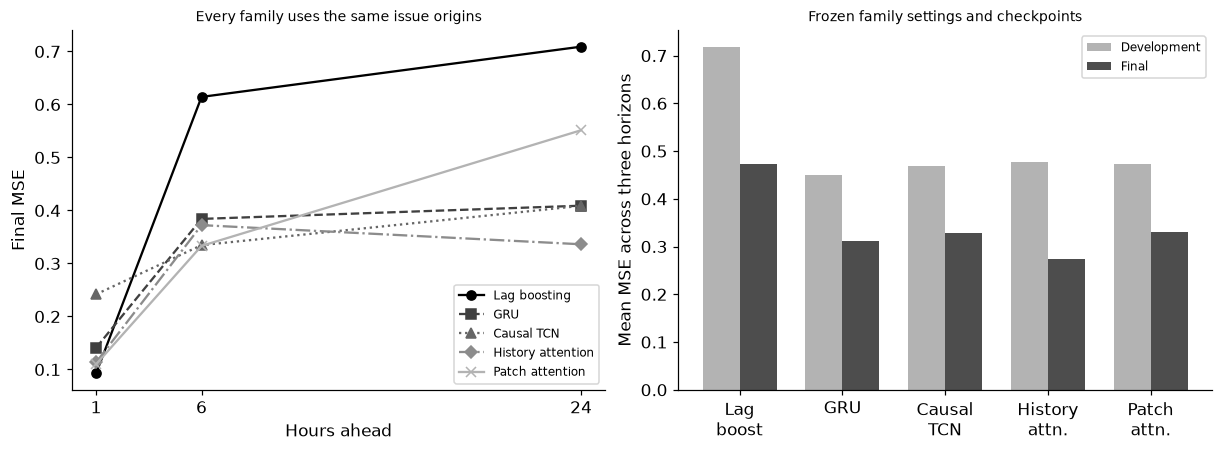

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4));styles=['o-','s--','^:','D-.','x-'];shades=['black','.25','.4','.55','.7']
for row,style,color in zip(rows,styles,shades):axes[0].plot(horizons,row['MSE_by_horizon'],style,color=color,label=row['model'])
axes[0].set(xticks=horizons,xlabel='Hours ahead',ylabel='Final MSE',title='Every family uses the same issue origins');axes[0].legend(fontsize=8)
xx=np.arange(len(rows));axes[1].bar(xx-.18,[r['development_MSE'] for r in rows],width=.36,color='.7',label='Development');axes[1].bar(xx+.18,[r['final_MSE'] for r in rows],width=.36,color='.3',label='Final');axes[1].set(xticks=xx,xticklabels=['Lag\nboost','GRU','Causal\nTCN','History\nattn.','Patch\nattn.'],ylabel='Mean MSE across three horizons',title='Frozen family settings and checkpoints');axes[1].legend(fontsize=8);plt.show()
assert all(np.isfinite(r['final_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_123','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['native lag-feature histogram boosting', 'actual GRU causal TCN and attention forecasts', 'actual nonoverlapping patch tokens', 'common multi-horizon information budget', 'development checkpoint and horizon-specific errors'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["native lag-feature histogram boosting", "actual GRU causal TCN and attention forecasts", "actual nonoverlapping patch tokens", "common multi-horizon information budget", "development checkpoint and horizon-specific errors"], "elapsed_seconds": 14.785, "example_id": "code_123", "hardware": "Darwin arm64 CPU", "results": {"TCN_prefix_max_difference": 0.0, "TCN_receptive_span": 63, "building_count": 8, "candidates": [{"development_MSE": 0.7243733204053274, "family": "Lag boosting", "max_leaf_nodes": 7}, {"development_MSE": 0.7170210762999332, "family": "Lag boosting", "max_leaf_nodes": 15}, {"best_step": 300, "development_MSE": 0.4853945836313141, "family": "GRU", "rate": 0.003}, {"best_step": 240, "development_MSE": 0.44908386874360584, "family": "GRU", "rate": 0.01}, {"best_step": 160, "development_MSE": 0.47523837967937327, "family": "Causal TCN", "rate": 0.003}, {"best_step": 100, "development_MSE": 0.46864399361914455, "family": "Cau